# 05 · Logistic regression: tuning and what the coefficients say

**Course topic 3 (logistic regression).** Starts from model B in `00_baseline` (ratings one-hot, scaled,
validation AUC 0.94767). We try different regularization strengths (C) and L2 vs L1, on the team split
(`make_split`), then read the coefficients of the best model.

Smaller C = stronger regularization (simpler model). L1 can set coefficients exactly to zero.

In [1]:
import sys, time
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from src.clean import load_data, make_features, make_split

train, test = load_data()
X, y, X_test = make_features(train, test, ratings_as_categories=True)
X_tr, X_va, y_tr, y_va = make_split(X, y)
scaler = StandardScaler().fit(X_tr)
Z_tr, Z_va = scaler.transform(X_tr), scaler.transform(X_va)
print('columns:', X.shape[1])

columns: 90


In [2]:
runs = [('l2', C) for C in (0.01, 0.1, 1, 10)] + [('l1', C) for C in (0.01, 0.1, 1)]
rows, models = [], {}
for penalty, C in runs:
    t = time.time()
    if penalty == 'l2':
        m = LogisticRegression(C=C, max_iter=3000)
    else:
        m = LogisticRegression(C=C, l1_ratio=1, solver='saga', max_iter=200, tol=1e-3, random_state=0)   # l1_ratio=1 = L1 (lasso)
    m.fit(Z_tr, y_tr)
    auc = roc_auc_score(y_va, m.predict_proba(Z_va)[:, 1])
    rows.append({'penalty': penalty.upper(), 'C': C, 'validation AUC': round(auc, 5),
                 'non-zero coefficients': int((m.coef_ != 0).sum()), 'seconds': round(time.time() - t)})
    models[(penalty, C)] = m
    print(rows[-1])
results = pd.DataFrame(rows)
results

{'penalty': 'L2', 'C': 0.01, 'validation AUC': 0.94766, 'non-zero coefficients': 90, 'seconds': 3}


{'penalty': 'L2', 'C': 0.1, 'validation AUC': 0.94767, 'non-zero coefficients': 90, 'seconds': 4}


{'penalty': 'L2', 'C': 1, 'validation AUC': 0.94767, 'non-zero coefficients': 90, 'seconds': 2}


{'penalty': 'L2', 'C': 10, 'validation AUC': 0.94767, 'non-zero coefficients': 90, 'seconds': 3}


{'penalty': 'L1', 'C': 0.01, 'validation AUC': 0.94764, 'non-zero coefficients': 76, 'seconds': 117}


{'penalty': 'L1', 'C': 0.1, 'validation AUC': 0.94767, 'non-zero coefficients': 79, 'seconds': 94}


{'penalty': 'L1', 'C': 1, 'validation AUC': 0.94767, 'non-zero coefficients': 90, 'seconds': 15}


,penalty,C,validation AUC,non-zero coefficients,seconds
0,L2,0.01,0.94766,90,3
1,L2,0.10,0.94767,90,4
2,L2,1.00,0.94767,90,2
3,L2,10.00,0.94767,90,3
4,L1,0.01,0.94764,76,117
5,L1,0.10,0.94767,79,94
6,L1,1.00,0.94767,90,15


## Coefficients of the best model

best: L2 C=0.1  AUC 0.94767  (baseline 0.94767)


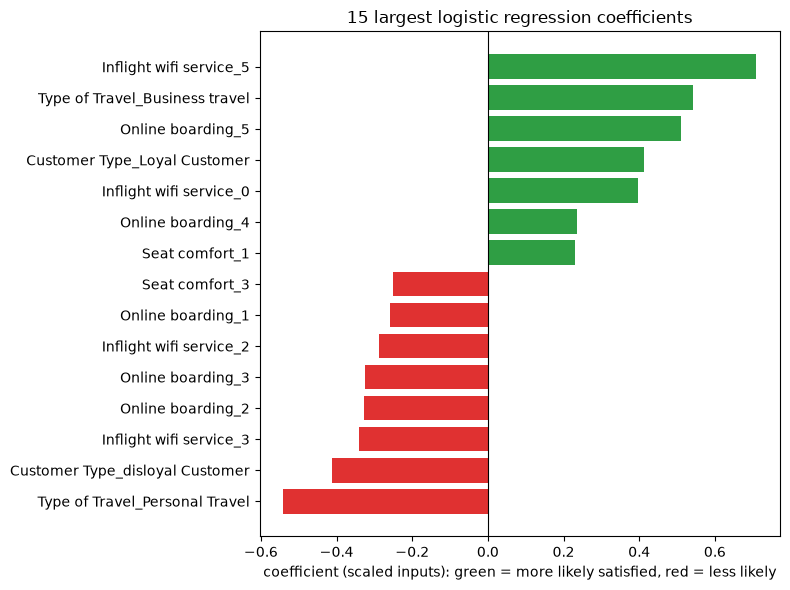

Inflight wifi service_5            0.710
Type of Travel_Business travel     0.541
Online boarding_5                  0.511
Customer Type_Loyal Customer       0.413
Inflight wifi service_0            0.397
Online boarding_4                  0.236
Seat comfort_1                     0.230
Seat comfort_3                    -0.251
Online boarding_1                 -0.259
Inflight wifi service_2           -0.287
Online boarding_3                 -0.326
Online boarding_2                 -0.329
Inflight wifi service_3           -0.340
Customer Type_disloyal Customer   -0.413
Type of Travel_Personal Travel    -0.541
dtype: float64

In [3]:
best = results.loc[results['validation AUC'].idxmax()]
best_model = models[(best['penalty'].lower(), best['C'])]
print(f"best: {best['penalty']} C={best['C']}  AUC {best['validation AUC']}  (baseline 0.94767)")

coef = pd.Series(best_model.coef_[0], index=X.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:15]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=['#2f9e44' if v > 0 else '#e03131' for v in top.values])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('coefficient (scaled inputs): green = more likely satisfied, red = less likely')
ax.set_title('15 largest logistic regression coefficients')
plt.tight_layout(); plt.savefig('../report/figures/logistic_coefficients.png', dpi=150); plt.show()
top.sort_values(ascending=False).round(3)